# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 135.3 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <ArrowStringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


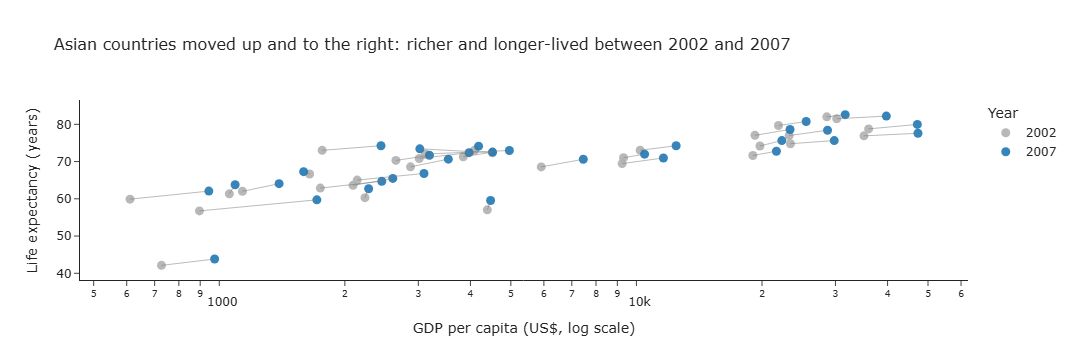

In [4]:
# Task 1
import plotly.express as px
import plotly.graph_objects as go

asia = df.loc[(df['continent'] == 'Asia') & (df['year'].isin([2002, 2007]))].copy()
asia['year'] = asia['year'].astype(str)

fig = px.scatter(
    asia,
    x='gdpPercap',
    y='lifeExp',
    color='year',
    color_discrete_map={'2002': '#B0B0B0', '2007': '#1F77B4'},
    category_orders={'year': ['2002', '2007']},
    hover_name='country',
    log_x=True,
    labels={
        'gdpPercap': 'GDP per capita (US$, log scale)',
        'lifeExp': 'Life expectancy (years)',
        'year': 'Year',
    },
    title='Asian countries moved up and to the right: richer and longer-lived between 2002 and 2007',
)

# Connect each country's 2002 point to its 2007 point
for country, g in asia.groupby('country'):
    g = g.sort_values('year')
    fig.add_trace(go.Scatter(
        x=g['gdpPercap'], y=g['lifeExp'],
        mode='lines',
        line=dict(color='rgba(120,120,120,0.5)', width=1),
        showlegend=False,
        hoverinfo='skip',
    ))

fig.update_traces(marker=dict(size=9, opacity=0.9), selector=dict(mode='markers'))
fig.update_layout(template='simple_white', title_font_size=16)
fig.show()

## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


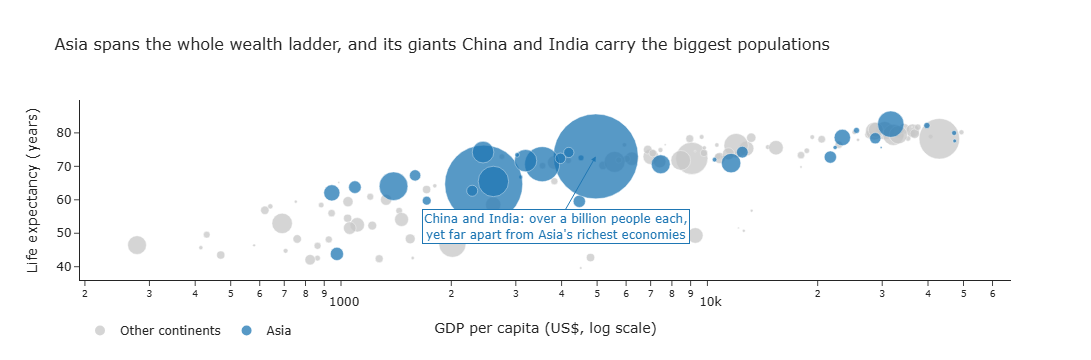

In [5]:
# Task 2
import numpy as np
import plotly.express as px

d07 = df.loc[df['year'] == 2007].copy()
d07['group'] = np.where(d07['continent'] == 'Asia', 'Asia', 'Other continents')
d07['order'] = (d07['group'] == 'Asia').astype(int)
d07 = d07.sort_values('order')

fig = px.scatter(
    d07,
    x='gdpPercap',
    y='lifeExp',
    size='pop',
    size_max=60,                      
    color='group',                    
    color_discrete_map={'Asia': '#1F77B4', 'Other continents': '#C8C8C8'},
    category_orders={'group': ['Other continents', 'Asia']},
    hover_name='country',
    hover_data={'group': False, 'continent': True, 'pop': ':,', 'gdpPercap': ':,.0f', 'lifeExp': ':.1f'},
    log_x=True,                      
    labels={
        'gdpPercap': 'GDP per capita (US$, log scale)',
        'lifeExp': 'Life expectancy (years)',
        'group': '',
    },
    title='Asia spans the whole wealth ladder, and its giants China and India carry the biggest populations',
)

fig.update_traces(marker=dict(opacity=0.75, line=dict(width=0.5, color='white')))

china = d07.loc[d07['country'] == 'China'].iloc[0]
fig.add_annotation(
    x=np.log10(china['gdpPercap']),
    y=china['lifeExp'],
    text="China and India: over a billion people each,<br>yet far apart from Asia's richest economies",
    showarrow=True,
    arrowhead=2,
    ax=-40, ay=70,
    font=dict(size=12, color='#1F77B4'),
    bgcolor='white',
    bordercolor='#1F77B4',
)

fig.update_layout(
    template='simple_white',
    title_font_size=16,
    legend=dict(orientation='h', y=-0.2),
)
fig.show()